# Lab 01: How to build a tool-calling agent

**CPU | API key: `OPENAI_API_KEY` | Follows: Day 1 D1-M03, steps 3.2 to 3.6 (slides 61–101)**

## Goal

In Lab 00 the model answered a question about Chinook's download links fluently and wrongly. In this lab you give it
a tool and run the tool call round trip yourself: the model asks for `get_policy`, your code runs it, you send the
result back, and the model answers from the policy. Then you let `create_agent` run the same loop and count its model
calls. The moment that teaches it: the same question that got a confident wrong answer now takes two or three model
calls, and the tool ran in your code each time, never in the model.

## What you will learn

- How to build the chat client from `models.env`, what each argument does, and why `reasoning_effort` is left out for
  `gpt-4o-mini`.
- How to read a model's reply (its text, its tool calls and its token counts), and why a fluent answer can still be
  wrong.
- How a tool's signature and docstring become the schema the model reads.
- How to run one tool call round trip by hand: the model asks, your code runs the tool, you send the result back, and
  the model answers.
- How `create_agent` runs the same loop for you, and how to count its model calls and tokens.
- How to recognise the older `prompt | model | parser` and `LLMChain` styles in code you read.

| Part | What you do | Calls to OpenAI |
|---|---|---|
| A | Build the chat client by hand, ask one question, read the reply and its token usage; optionally, watch reasoning effort on a reasoning model | 2 (one is refused), plus 4 in the optional demo |
| B | An aside: recognise two older ways of joining a prompt and a model | 1 |
| C | Write the `get_policy` tool and read the schema the model receives | 0 |
| D | Run the tool call round trip by hand, then let `create_agent` run the loop | 4 to 6 |
| E | Label every message of your agent run | 0 |

The whole lab uses a few thousand tokens: well under one US cent with `gpt-4o-mini`. The optional demo at the end of
Part A calls a reasoning model, `gpt-5`, four times, for a few US cents; switch it off if your account cannot use it.

## The first two cells

These are the same two cells that open Lab 00, which explains each line. **Setup** finds the repository folder (on
Colab it copies the repository and installs the packages first). **Config** reads the model names from `models.env`
and finds your key without printing it.

In [1]:
# Setup: on Colab, copy the repository and install the packages. Locally (after uv sync) nothing is installed.
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not Path("/content/agentic_ai_conversational_agents").exists():
        !git clone -q --depth 1 https://github.com/tatwan/agentic_ai_conversational_agents.git /content/agentic_ai_conversational_agents
    %cd /content/agentic_ai_conversational_agents
    %pip install -q -r requirements.txt

ROOT = next(folder for folder in [Path.cwd(), *Path.cwd().parents] if (folder / "models.env").exists())
sys.path.insert(0, str(ROOT))
print("Repository folder:", ROOT.name)

Repository folder: agentic_ai_conversational_agents


⚠️ On Colab, run the setup cell first in a fresh session. If another cell loaded the old `openai` package before the
install, Part A fails with `ImportError: cannot import name ... from 'openai...'`; use **Runtime → Restart session**
and run from the top.

In [2]:
# Config: model names come from models.env; the key from the environment, .env or Colab Secrets.
from shared.settings import load_settings, load_key

settings = load_settings()
key_found_in = load_key("OPENAI_API_KEY")

for name in ("CHAT_MODEL", "REASONING_EFFORT", "JUDGE_MODEL", "EMBED_MODEL"):
    print(f"{name:18}{settings[name] or '(not set)'}")
print(f"{'OPENAI_API_KEY':18}{'found in ' + key_found_in if key_found_in else 'not found'}")

CHAT_MODEL        gpt-4o-mini
REASONING_EFFORT  (not set)
JUDGE_MODEL       gpt-4o-mini
EMBED_MODEL       text-embedding-3-small
OPENAI_API_KEY    found in .env


`CHAT_MODEL` is the model every call in this lab uses. `REASONING_EFFORT` is empty; Part A shows why.

The picture shows where the lab ends: one agent turn in which the model asks for a tool and your code runs it. Parts A
to C build the pieces; Part D runs the whole turn.

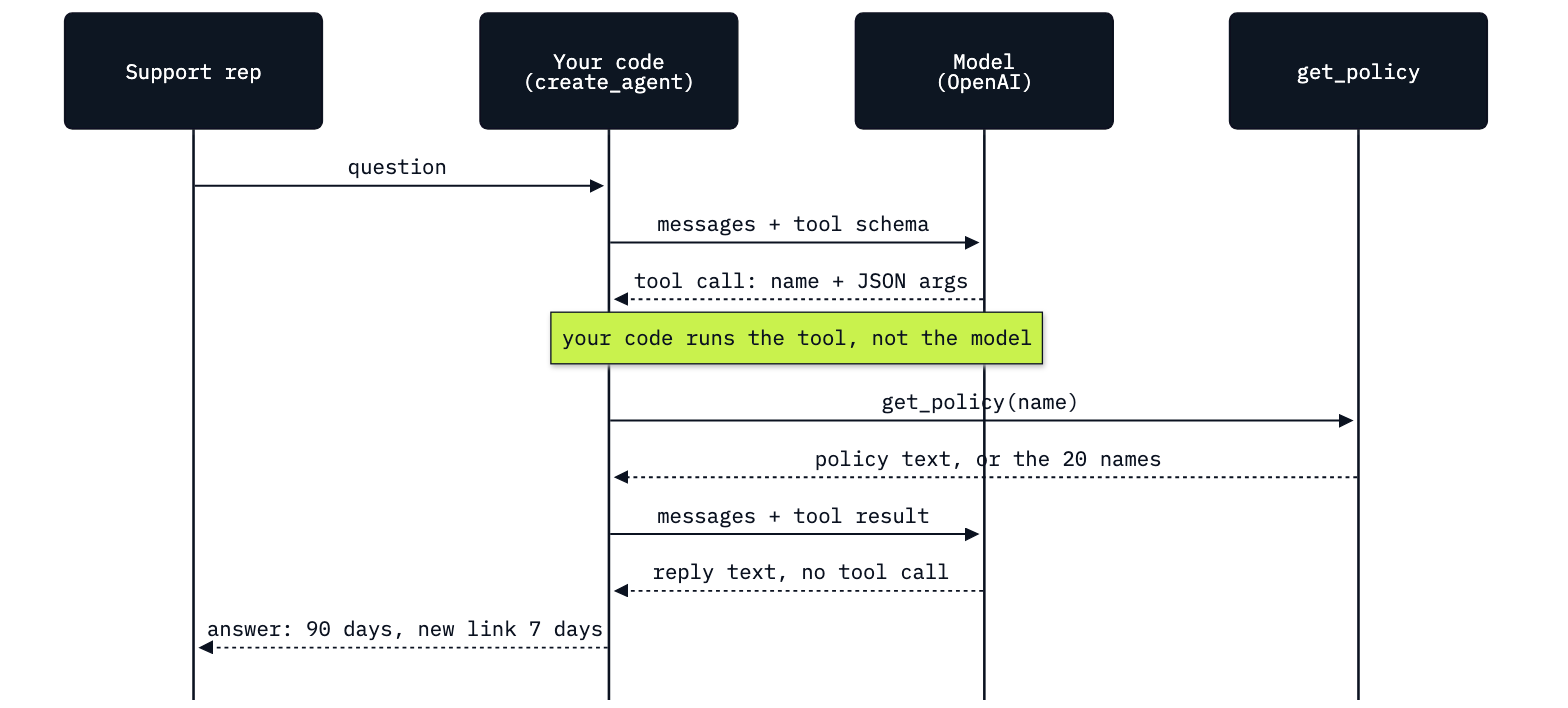

In [3]:
from IPython.display import Image
Image(filename=ROOT / "01_First_Chain_And_Tool" / "resources" / "lab01_tool_call.png", width=760)

---

## Part A: One model call and its token usage

The copilot talks to OpenAI through `ChatOpenAI` from the `langchain-openai` package. Lab 00 built it with
`shared.settings.chat_model()`; here you build it by hand to see each argument. Later labs use `chat_model()`
again, which does what the next cell does.

- `model=settings["CHAT_MODEL"]` is the model's name, read from `models.env`, so no notebook has a model name in its
  code. Today it is `gpt-4o-mini`.
- `use_responses_api=True` sends the request through OpenAI's
  [Responses API](https://developers.openai.com/api/docs/guides/migrate-to-responses), which OpenAI recommends for
  new projects. If you leave it out, `langchain-openai` picks the API from the model and the request, and a plain
  `gpt-4o-mini` call goes through the older Chat Completions API. The answers are similar, but the response metadata
  and some features differ, so we set it and every lab takes the same path.
- There is no `api_key` argument: the client reads `OPENAI_API_KEY` from the environment, where the config cell put it.
- Everything else keeps its default: no `temperature` (the model's own default applies), no limit on the reply's
  length, and the `openai` library's default retries and timeout.

In [4]:
from langchain_openai import ChatOpenAI

model = ChatOpenAI(
    model=settings["CHAT_MODEL"],
    use_responses_api=True,
)
print(model.model_name, "| Responses API:", model.use_responses_api)

gpt-4o-mini | Responses API: True


### The `reasoning_effort` argument

Code written for a reasoning model often builds the same client with a third argument, `reasoning_effort="low"`. A
reasoning model, such as `gpt-5` or `gpt-6-luna`, writes hidden reasoning tokens before its answer, and
`reasoning_effort` (for example `low`, `medium` or `high`) sets how much it reasons. More effort can help with a hard
question; it also costs output tokens and seconds. `gpt-4o-mini` is not a reasoning model and has no such setting, so
`models.env` leaves `REASONING_EFFORT` empty and the cell above does not pass it. The end of Part A shows the
setting on a reasoning model.

Predict: what happens if you pass it anyway? The next cell tries. On a model without reasoning it catches the error,
so the notebook keeps going; a refused request uses no tokens. On a reasoning model the call goes through.

In [5]:
import openai

print("CHAT_MODEL:", settings["CHAT_MODEL"])
print("REASONING_EFFORT in models.env:", repr(settings["REASONING_EFFORT"]))
try:
    test = ChatOpenAI(model=settings["CHAT_MODEL"], use_responses_api=True, reasoning_effort="low").invoke("Hi")
except openai.BadRequestError as error:
    # a model without a reasoning step, such as gpt-4o-mini
    print("Refused with status", error.status_code)
    print(error.body["message"])
else:
    # a reasoning model: the argument is valid
    print("Accepted: this model has a reasoning step.")
    print("Reasoning tokens:", test.usage_metadata["output_token_details"].get("reasoning", 0))

CHAT_MODEL: gpt-4o-mini
REASONING_EFFORT in models.env: ''


Refused with status 400
Unsupported parameter: 'reasoning.effort' is not supported with this model.


When we ran it (`gpt-4o-mini`, 11 Oct 2026), OpenAI refused the request with status 400 before the model ran. Code
copied from an example written for a reasoning model fails this way on `gpt-4o-mini`. If `models.env` names a
reasoning model, the cell prints *Accepted* and the reasoning tokens instead (a short *Hi* may need none). Either
way, `shared.settings.chat_model()` passes the argument only when `REASONING_EFFORT` has a value, so moving the labs
to a reasoning model is a change to `models.env`, not to the notebooks.

### Ask the question

A call sends a list of messages and gets one message back. Each message has a role and content: `system` for your
instructions, `user` for the rep's question. LangChain accepts plain `(role, content)` pairs and turns them into
`SystemMessage` and `HumanMessage` objects. Nothing from earlier calls is added: the list you send is all the model
sees.

The question is the one from Lab 00. Chinook's answer is in `data/corpus/policy_digital_downloads.md`, and this call
does not include that file. Predict: will the reply give Chinook's rule?

In [6]:
question = "How long does a digital download link last?"
reply = model.invoke([
    ("system", "You help Chinook support reps. Be brief."),
    ("user", question),
])
print(reply.text)

A digital download link typically lasts for 24 to 48 hours, but it can vary by service. Please check the specific terms for your purchase.


When we ran it (`gpt-4o-mini`, 11 Oct 2026), the reply said a link *typically lasts for 24 to 48 hours, but it can vary by service*. Earlier runs with
`gpt-4o-mini` (10 and 11 Oct 2026) said *24 to 72 hours*, *7 to 30 days*, *30 days*, and once that a link *from Chinook typically lasts for 30 days*,
naming a shop whose rules the model had never seen. A reference run with `gpt-6-luna` (5 Oct 2026) said *24 hours*.

Now read the policy the answer should have come from.

In [7]:
policy_file = ROOT / "data" / "corpus" / "policy_digital_downloads.md"
print(policy_file.read_text())

# Digital downloads

A digital album is available for download for 90 days after purchase. After that the link expires. The customer can request one new link; it lasts 7 days.

Downloads are tied to the customer email on the invoice. We do not send a second copy to a different email.

There is no return and no refund on a completed download unless the file is corrupt. Then we re-issue the link.



### Compare the reply with the policy

Chinook gives 90 days after purchase, and one new link that lasts 7 days. Our reply, 24 to 48 hours, matches
neither. Nothing in the reply says it is a guess. It reads as sure as a correct answer would.

The code ran, the answer is fluent, and it is wrong. You only catch a mistake like this by comparing the answer with
the source. The model answered from what it learned in training, because the policy was not in the request.

| Source of the answer | In this request? |
|---|---|
| `policy_digital_downloads.md`: *available for download for 90 days after purchase* | no |
| the model's training data | yes, always |
| your instructions: *Be brief* | yes |

The rest of the lab gives the model a way to ask for the policy.

First, look at what came back. `reply` is an `AIMessage`. Besides `.text`, it holds any tool calls (none here: the
model had no tools) and the token counts.

In [8]:
print(type(reply).__name__)
print("tool_calls:", reply.tool_calls)
print(reply.usage_metadata)

AIMessage
tool_calls: []
{'input_tokens': 30, 'output_tokens': 31, 'total_tokens': 61, 'input_token_details': {'cache_creation': 0, 'cache_read': 0}, 'output_token_details': {'reasoning': 0}}


`usage_metadata` is LangChain's standard record of the call's tokens.

| Field | Meaning | Our run (`gpt-4o-mini`, 11 Oct 2026) |
|---|---|---|
| `input_tokens` | everything sent: the two messages, and the tool schemas when there are tools | 30 |
| `output_tokens` | the reply, including any reasoning tokens | 31 |
| `total_tokens` | input plus output | 61 |
| `input_token_details.cache_read` | input served from OpenAI's prompt cache | 0 |
| `output_token_details.reasoning` | hidden reasoning tokens | 0 |

`gpt-4o-mini` has no reasoning step, so its reasoning count is 0 and its output tokens are only the words you read.
A reasoning model counts its hidden reasoning here: a reference run with `gpt-6-luna` (5 Oct 2026) used 29 input and
207 output tokens, and 188 of the 207 were reasoning.

### Reasoning effort on a reasoning model (optional demo)

⚠️ The next two cells call the model named by `REASONING_MODEL` in `models.env`, `gpt-5`, four times. At $1.25 per
1M input and $10.00 per 1M output tokens (prices checked 10 Oct 2026), they cost about two US cents. If your account can use only
`gpt-4o-mini`, set `RUN_REASONING_DEMO = False` in the first cell and read our results in the markdown; nothing later
in the lab needs this demo.

The client is the one from the start of Part A with another model and one more argument, `reasoning_effort="low"`.

In [9]:
import time

RUN_REASONING_DEMO = True   # set to False if your account can use only gpt-4o-mini

if RUN_REASONING_DEMO:
    thinker = ChatOpenAI(
        model=settings["REASONING_MODEL"],
        use_responses_api=True,
        reasoning_effort="low",
    )
    thought = thinker.invoke([
        ("system", "You help Chinook support reps. Be brief."),
        ("user", question),
    ])
    print(thinker.model_name, "| reasoning_effort:", thinker.reasoning_effort)
    print(thought.text)
    print(thought.usage_metadata)

gpt-5 | reasoning_effort: low
It depends on the order/product. Please share your order number or the email used at checkout and I’ll check the exact expiry. If your link has expired, I can quickly resend or extend it.

Tip: You can also sign in to your account > Purchases/Library to regenerate the download link if available.
{'input_tokens': 29, 'output_tokens': 587, 'total_tokens': 616, 'input_token_details': {'cache_creation': 0, 'cache_read': 0}, 'output_token_details': {'reasoning': 512}}


When we ran it (`gpt-5`, 11 Oct 2026), low effort used 29 input and 587 output tokens, and 512 of
the 587 were reasoning: tokens the model wrote and you pay for as output, but never see. The visible reply was
the other 75. A reference run with `gpt-6-luna` (5 Oct 2026) used 29 input, 207 output and 188 reasoning tokens; an
earlier `gpt-5` run the same day used 258 output tokens, 192 of them reasoning. The reasoning count changes a lot
from run to run. This time the answer gave no period at all: *It depends on the order/product*, and it asked for an
order number. That is more careful than a made-up rule, but it still does not know Chinook's 90 days.

Now the same question at three effort levels. `gpt-5` accepts `minimal`, `low`, `medium` and `high`; newer
models such as `gpt-6-luna` also accept `none`. Predict: does more reasoning bring the answer to 90 days?

In [10]:
if RUN_REASONING_DEMO:
    for effort in ("minimal", "low", "high"):
        thinker = ChatOpenAI(model=settings["REASONING_MODEL"], use_responses_api=True, reasoning_effort=effort)
        start = time.perf_counter()
        thought = thinker.invoke([
            ("system", "You help Chinook support reps. Be brief."),
            ("user", question),
        ])
        seconds = time.perf_counter() - start
        usage = thought.usage_metadata
        print(f"{effort:8} reasoning {usage['output_token_details']['reasoning']:5}  "
              f"output {usage['output_tokens']:5}  {seconds:5.1f} s | {thought.text[:50]}")

minimal  reasoning     0  output    52   11.9 s | Digital download links are active for 48 hours fro


low      reasoning   384  output   461    5.3 s | By default, download links are active for 30 days 


high     reasoning  1920  output  2011   16.9 s | Download links are time‑limited. The exact expiry 


When we ran it (`gpt-5`, 11 Oct 2026):

| Effort | Reasoning tokens | Output tokens | Seconds | Answer |
|---|---|---|---|---|
| minimal | 0 | 52 | 11.9 | 48 hours |
| low | 384 | 461 | 5.3 | 30 days |
| high | 1,920 | 2,011 | 16.9 | *time-limited*, no period in the printed start |

More effort bought more reasoning tokens: `high` produced about 39 times the output tokens of `minimal` (2,011
against 52) and took the longest, 16.9 s. Seconds are noisier than tokens: the `minimal` call took 11.9 s with no
reasoning at all, because a call also waits on the network and the service. Compare token counts, and time several
runs before you trust a duration (Lab 10 measures it). No answer gave Chinook's 90 days. The model reasons over what is in the request, and the policy was not in it. Effort helps with questions the model can work out from what it has; a
question about the shop's own rules needs the policy, which Parts C and D give it. The same `low` setting gave 512
reasoning tokens in the cell before and 384 here: the count changes from run to run.

### Checkpoint A

The wording and the token counts change from run to run, so check the facts.

| You should see | Value from our run (`gpt-4o-mini` and `gpt-5`, 11 Oct 2026) |
|---|---|
| The client | `gpt-4o-mini`, Responses API `True` |
| `reasoning_effort="low"` on `gpt-4o-mini` | refused with status 400: `Unsupported parameter: 'reasoning.effort' is not supported with this model.` (on a reasoning model: *Accepted*) |
| The reply | a period that is not Chinook's 90 days (ours: 24 to 48 hours) |
| `reply.tool_calls` | `[]` |
| `usage_metadata` | 30 input, 31 output, 0 reasoning (yours will be close) |
| Optional demo, one call | `gpt-5`, effort `low`; reasoning tokens counted inside output tokens (ours: 512 of 587) |
| Optional demo, three efforts | reasoning tokens rise from `minimal` to `high` (ours: 0, 384, 1,920); seconds vary (ours: 11.9, 5.3, 16.9 s); no answer gives 90 days |

---

## Part B: Recognise an older composition style (an aside)

This part is an aside for reading older code; nothing later in the lab depends on it. Many tutorials from 2023 and
2024 join a prompt template, a model and a parser with the `|` operator, a style called LCEL (LangChain Expression
Language). It still runs, but it is an older style: the current LangChain documentation builds agents with
`create_agent` (Part D) and fixed sequences of steps as LangGraph workflows, which Lab 09 builds. Run it once here
so you recognise it.

A **prompt template** is a list of messages with gaps, here `{n}` and `{question}`, that `invoke` fills in.
`StrOutputParser` keeps only the text of the model's reply. The `|` joins the three so that each one's output becomes
the next one's input.

In [11]:
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate

prompt = ChatPromptTemplate.from_messages([
    ("system", "You help Chinook reps. Answer in {n} sentences."),
    ("user", "{question}"),
])
chain = prompt | model | StrOutputParser()

answer = chain.invoke({"n": 2, "question": question})
print(type(chain).__name__, "| returns a string:", isinstance(answer, str))
print(answer)

RunnableSequence | returns a string: True
A digital download link typically lasts for 7 to 30 days, depending on the provider's policy. After this period, the link may expire, requiring a new download or purchase.


Read the chain from left to right. The template turned the dictionary into two messages, the model returned an
`AIMessage`, and the parser kept its text, so the chain returned a string, not a message. The order is fixed in your
code: the model cannot stop halfway to fetch a policy. When we ran it (`gpt-4o-mini`, 11 Oct 2026), the answer was two
sentences, as `{n}` asked: *A digital download link typically lasts for 7 to 30 days, depending on the provider's policy. After this period, the link may expire, requiring a new download or purchase.* Still not 90 days. The template changed the form of the answer, not what the
model knows.

`LLMChain` is older still. It imports from the `langchain-classic` package and warns when you create one. We only
want the warning, so we give it `FakeListLLM`, a stand-in model that returns a fixed string: no call is made.
`warnings.catch_warnings(record=True)` collects the warning so we can print it as plain text.

In [12]:
import warnings
from langchain_core.language_models.fake import FakeListLLM
from langchain_core.prompts import PromptTemplate

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    from langchain_classic.chains import LLMChain
    old_chain = LLMChain(llm=FakeListLLM(responses=["ok"]), prompt=PromptTemplate.from_template("{q}"))

for w in caught:
    if "LLMChain" in str(w.message):
        print(w.category.__name__)
        print(w.message)

LangChainDeprecationWarning
The class `LLMChain` was deprecated in LangChain 0.1.17 and will be removed in 2.0.0. Use `RunnableSequence, e.g., `prompt | llm`` instead.


The warning points to `prompt | llm`, the style in the cell before. When you meet either in a tutorial, read it as a
fixed sequence (fill the prompt, call the model, keep the text) and write new code the way the rest of these labs
do. `langchain-classic` is installed only for this cell.

### Checkpoint B

| You should see | Value from our run (`gpt-4o-mini`, 11 Oct 2026) |
|---|---|
| The chain | `RunnableSequence`, `returns a string: True`; two sentences that still do not give 90 days |
| The `LLMChain` cell | `LangChainDeprecationWarning`: *The class `LLMChain` was deprecated in LangChain 0.1.17 and will be removed in 2.0.0.* |

---

## Part C: A tool and its schema

A **tool** is a function the model can ask your code to run. It has a name, a description and typed arguments. The
model never runs it: it sends back a **tool call**, a tool name with JSON arguments, and your code decides whether
to run the function.

`get_policy` returns the text of one Chinook policy file. Start with the folder and the names the tool will accept.

In [13]:
CORPUS = ROOT / "data" / "corpus"
POLICIES = sorted(path.stem.removeprefix("policy_") for path in CORPUS.glob("policy_*.md"))
print(len(POLICIES), "policies")
print(POLICIES)

20 policies
['accounts', 'cancellations', 'damaged_media', 'data_retention', 'digital_downloads', 'escalations', 'exchanges', 'gift_cards', 'international', 'library', 'payment', 'preorders', 'privacy', 'refunds', 'returns', 'shipping', 'student_discount', 'support_hours', 'support_reps', 'warranty']


Now the tool. Three parts of it reach the model:

- `@tool(parse_docstring=True)` turns the function into a LangChain tool and reads its docstring in the Google
  style (a summary, then an `Args:` section).
- The signature, `name: str`, becomes the tool's one argument and its type.
- The docstring becomes the description the model reads: the first lines say what the tool does and when to call it,
  and the `Args:` line describes the argument.

When the name is unknown, the function returns text that lists the valid names instead of raising an error. The
last cell of this part shows why.

In [14]:
from langchain.tools import tool

@tool(parse_docstring=True)
def get_policy(name: str) -> str:
    """Return the full text of one Chinook support policy.

    Call it before answering any question about shop rules.

    Args:
        name: Policy name, e.g. "refunds" or "escalations".
    """
    path = CORPUS / f"policy_{name}.md"
    if not path.exists():
        known = ", ".join(POLICIES)
        return f"No policy named {name!r}. Known: {known}."
    return path.read_text(encoding="utf-8")

print(type(get_policy).__name__, "|", get_policy.name)

StructuredTool | get_policy


The decorator replaced the function with a tool object. Read what LangChain took from the function.

In [15]:
print("description:", get_policy.description)
print("args:", get_policy.args)

description: Return the full text of one Chinook support policy. Call it before answering any question about shop rules.
args: {'name': {'description': 'Policy name, e.g. "refunds" or "escalations".', 'title': 'Name', 'type': 'string'}}


The model receives this as JSON, in OpenAI's function-calling format. `convert_to_openai_tool` shows that form
without sending anything.

In [16]:
import json
from langchain_core.utils.function_calling import convert_to_openai_tool

print(json.dumps(convert_to_openai_tool(get_policy), indent=1))

{
 "type": "function",
 "function": {
  "name": "get_policy",
  "description": "Return the full text of one Chinook support policy. Call it before answering any question about shop rules.",
  "parameters": {
   "properties": {
    "name": {
     "description": "Policy name, e.g. \"refunds\" or \"escalations\".",
     "type": "string"
    }
   },
   "required": [
    "name"
   ],
   "type": "object"
  }
 }
}


That is all the model learns about the tool: a name, a description and a schema with one required string, `name`.
The code inside the function never reaches the model, so the model does not know the 20 policy names. The description
gives two examples, and the model has to guess the rest. Part D shows what happens when it guesses.

Now run the tool yourself, the way `create_agent` will. First a name that exists.

In [17]:
print(get_policy.invoke({"name": "escalations"}))

# Escalations

Escalate when:

- a refund over 100 dollars is requested
- the same customer has three open tickets
- a representative wants to override a written policy

Escalations go to the support manager. The assigned representative stays on the ticket.

This shop does not publish the manager's personal phone number. Do not invent one.



Now a name that does not exist. Predict: an exception, an empty string, or something else?

In [18]:
print(get_policy.invoke({"name": "vip"}))

No policy named 'vip'. Known: accounts, cancellations, damaged_media, data_retention, digital_downloads, escalations, exchanges, gift_cards, international, library, payment, preorders, privacy, refunds, returns, shipping, student_discount, support_hours, support_reps, warranty.


Text, not an exception. If the function raised an error, the agent run in Part D would stop with it. Returned as
text, it goes back to the model as the tool's result, and the list of 20 names gives the model what it needs to try
again.

### Checkpoint C

| You should see | Value from our run |
|---|---|
| `POLICIES` | 20 names, from `accounts` to `warranty` |
| Tool name and argument | `get_policy`, one required string `name` |
| Description | *Return the full text of one Chinook support policy. Call it before answering any question about shop rules.* |
| `get_policy("escalations")` | the escalations policy, starting `# Escalations` |
| `get_policy("vip")` | `No policy named 'vip'. Known: accounts, cancellations, ...` with all 20 names |

This part made no model call, so your output matches ours exactly.

---

## Part D: The agent decides

First one step by hand, to see who does what. `bind_tools` attaches the tool's schema to every request the model
receives. It does not give the model any way to run the function.

Ask Part A's question again, with a system prompt that tells the model to check the policy. Predict: will the reply
have any text?

In [19]:
model_with_tools = model.bind_tools([get_policy])
conversation = [
    ("system", "You help Chinook support reps. Check the policy before you answer."),
    ("user", question),
]
first = model_with_tools.invoke(conversation)
print("text:", repr(first.text))
print("tool_calls:", first.tool_calls)

text: ''
tool_calls: [{'name': 'get_policy', 'args': {'name': 'digital downloads'}, 'id': 'call_IAlmjcng2X9jB7qHl6iwH6Zk', 'type': 'tool_call'}]


When we ran it (`gpt-4o-mini`, 11 Oct 2026), the reply had no text, only a tool call: `get_policy` with
`{'name': 'digital downloads'}`. That is a guess in plain words, and not one of the 20 file names (the file is
`digital_downloads`). Your run may guess the right name at once. Either way, nothing has run yet: the model has only
asked.

Our code now runs the function. Passing the whole tool call to `invoke`, not only its arguments, makes the tool
return a `ToolMessage`: the result, tagged with the call's id so the model can match the answer to its request.

In [20]:
tool_message = get_policy.invoke(first.tool_calls[0])
print(type(tool_message).__name__, "| tool_call_id:", tool_message.tool_call_id)
print(tool_message.content[:300])

ToolMessage | tool_call_id: call_IAlmjcng2X9jB7qHl6iwH6Zk
No policy named 'digital downloads'. Known: accounts, cancellations, damaged_media, data_retention, digital_downloads, escalations, exchanges, gift_cards, international, library, payment, preorders, privacy, refunds, returns, shipping, student_discount, support_hours, support_reps, warranty.


In our run the tool message is the error text with the 20 names, because the name was wrong. If your model guessed
the right name, it is the policy itself.

To finish the turn, send the model everything so far: the system prompt and the question, its own tool call
(`first`) and your tool's result. The model needs its own tool call in the list to match the result to the request by
`tool_call_id`. Predict: will the reply be text this time?

In [21]:
conversation += [first, tool_message]
second = model_with_tools.invoke(conversation)
print("text:", second.text[:300] if second.text else repr(second.text))
print("tool_calls:", second.tool_calls)

text: ''
tool_calls: [{'name': 'get_policy', 'args': {'name': 'digital_downloads'}, 'id': 'call_CUTt2yD6UsS49SnUj8wJacre', 'type': 'tool_call'}]


When we ran it (`gpt-4o-mini`, 11 Oct 2026), the second reply was not text: it was another tool call, now with
`digital_downloads`, the name taken from the error text. The model read your tool's result and corrected itself. When
the first name is right, the second reply is already the answer.

Either way you cannot know in advance how many rounds a question needs. A `while` loop runs every tool call the model
asks for and sends the results back, until the model replies with text and no tool call:

In [22]:
reply = second
while reply.tool_calls:
    conversation.append(reply)
    for call in reply.tool_calls:
        conversation.append(get_policy.invoke(call))
    reply = model_with_tools.invoke(conversation)
conversation.append(reply)

model_calls = sum(1 for message in conversation if getattr(message, "type", "") == "ai")
print(len(conversation), "messages, including the system prompt |", model_calls, "model calls")
print(reply.text)

7 messages, including the system prompt | 3 model calls
A digital album is available for download for 90 days after purchase. After that, the link expires. If needed, customers can request a new link, which lasts for 7 days. Note that the downloads are tied to the email on the invoice, and there’s no return or refund on completed downloads unless the file is corrupt. In that case, a new link can be issued.


In our run the loop went round once more: it ran `get_policy("digital_downloads")`, sent the policy back, and the
third reply was the answer, with the policy's two facts: the album is *available for download for 90 days after
purchase*, and a new link *lasts for 7 days*. The conversation holds seven messages (the system prompt, the question,
two tool calls, two tool messages, the answer) and three model calls. When the first name is right it ends with five
messages and two model calls.

Those few lines are the whole agent loop: call the model, run what it asks for, send the results back, and stop when
it answers in text. `create_agent` writes that loop for you. It takes the same model, the list of tools the model may
ask for, and a system prompt that starts every call.

In [23]:
from langchain.agents import create_agent

agent = create_agent(
    model,
    tools=[get_policy],
    system_prompt="You help Chinook support reps. Check the policy before you answer.",
)
print(type(agent).__name__)

CompiledStateGraph


`create_agent` returns a `CompiledStateGraph`, a LangGraph graph with a model step and a tool step. It loops between
them until a reply has no tool call. `invoke` takes a dictionary holding the conversation's messages and returns the
same dictionary with every message the run added.

In [24]:
result = agent.invoke({"messages": [("user", question)]})
messages = result["messages"]
print(len(messages), "messages")
print(messages[-1].text)

6 messages
A digital album download link is available for 90 days after purchase. After that, the link expires, but the customer can request one new link that lasts for an additional 7 days. Please note that downloads are tied to the customer's email on the invoice, and there are no returns or refunds on completed downloads unless the file is corrupt.


When we ran it (`gpt-4o-mini`, 11 Oct 2026), the run had six messages and the answer gave the two facts in
the policy: the link is *available for 90 days after purchase*, and a new link *lasts for an additional 7 days*. Check your answer for those two
facts, not for our wording.

Now print every message in the run: its type, its text, and any tool call.

In [25]:
for number, message in enumerate(messages, start=1):
    print(f"--- {number} {message.type}")
    if message.text:
        print(message.text[:160])
    for call in getattr(message, "tool_calls", []):
        print("tool call:", call["name"], call["args"])

--- 1 human
How long does a digital download link last?
--- 2 ai
tool call: get_policy {'name': 'digital download'}
--- 3 tool
No policy named 'digital download'. Known: accounts, cancellations, damaged_media, data_retention, digital_downloads, escalations, exchanges, gift_cards, intern
--- 4 ai
tool call: get_policy {'name': 'digital_downloads'}
--- 5 tool
# Digital downloads

A digital album is available for download for 90 days after purchase. After that the link expires. The customer can request one new link; i
--- 6 ai
A digital album download link is available for 90 days after purchase. After that, the link expires, but the customer can request one new link that lasts for an


Our run: the rep's question (1); a tool call with a name that does not exist, `digital download` (2); the
error text with the 20 names, returned by our code (3); a second tool call, now with `digital_downloads`, taken from
that list (4); the policy text (5); and the reply (6). The step by hand guessed `digital downloads` and the agent
`digital download`: the model chooses again on every call. It learned the right name from the tool's error text, which is why
`get_policy` returns text instead of raising an error. When the model guesses the right name at once, the run has
four messages: question, tool call, policy, reply.

Every `ai` message is one call to the model. List the calls with what each one returned and its token counts.

In [26]:
ai_messages = [message for message in messages if message.type == "ai"]
for number, message in enumerate(ai_messages, start=1):
    returned = "tool call" if message.tool_calls else "reply text"
    usage = message.usage_metadata
    print(f"call {number}: {returned:10}  input {usage['input_tokens']:4}  output {usage['output_tokens']:3}")

call 1: tool call   input   96  output  16
call 2: tool call   input  181  output  17
call 3: reply text  input  292  output  70


Three model calls answered one question: two returned tool calls, the last one the reply. The input grew from 96 to
181 to 292 tokens, because each call sends everything before it again: the system prompt, the question, the tool
calls and the tool results, including the whole policy text.

Run the agent cell, and the two after it, a few times. Six messages and four messages are both correct runs; what
must hold is the facts in the answer.

### Checkpoint D

| You should see | Value from our run (`gpt-4o-mini`, 11 Oct 2026) |
|---|---|
| The step by hand | `text: ''` and one tool call to `get_policy` (ours: `digital downloads`, a wrong name); then a `ToolMessage` with the same `tool_call_id` |
| Sending the result back | text and no tool call when the first name was right; another tool call when it was wrong (ours: `digital_downloads`) |
| The loop by hand | ends with text and no tool call: 90 days after purchase, one new link that lasts 7 days (ours: 7 messages with the system prompt, 3 model calls; the loop went round once) |
| `create_agent` | `CompiledStateGraph` |
| The answer | 90 days after purchase; one new link that lasts 7 days |
| Messages and model calls | 4 messages and 2 calls when the first name is right, 6 and 3 after one wrong name (ours: 6 messages and 3 calls, `digital download` first) |
| Input tokens | grow with each call (ours: 96, 181, 292) |

---

## Part E: Label the run

One turn of the copilot has seven steps: **1** receive, **2** load thread, **3** build context, **4** call model,
**5** run tools, **6** stream reply, **7** save checkpoint. Steps 2, 3 and 7 handle memory, which
this agent does not have yet (Lab 03), so your run uses steps 1, 4, 5 and 6.

For each message of your own run, write down on paper:

1. its role (user, assistant with a tool call, tool, assistant with a reply);
2. who produced it: the rep, the model, or your code;
3. the turn step (1 to 7) that produced it.

Then count the model calls. The cell prints the rows to label.

In [27]:
for number, message in enumerate(messages, start=1):
    if message.text:
        shown = message.text[:60].replace("\n", " ")
    else:
        shown = f"tool call: {message.tool_calls[0]['args']}"
    print(f"{number} | {message.type:5} | {shown}")

1 | human | How long does a digital download link last?
2 | ai    | tool call: {'name': 'digital download'}
3 | tool  | No policy named 'digital download'. Known: accounts, cancell
4 | ai    | tool call: {'name': 'digital_downloads'}
5 | tool  | # Digital downloads  A digital album is available for downlo
6 | ai    | A digital album download link is available for 90 days after


### Check your table

Our run had six messages.

| # | Role | Produced by | Turn step |
|---|---|---|---|
| 1 | user | the rep | 1 receive |
| 2 | assistant, tool call | the model | 4 call model |
| 3 | tool: the error text | your code: `get_policy` | 5 run tools |
| 4 | assistant, tool call | the model | 4 call model again |
| 5 | tool: the policy | your code: `get_policy` | 5 run tools |
| 6 | assistant, reply | the model | 4 call model again, then 6 stream reply |

That is three model calls. A four-message run has no rows 3 and 4: the first tool call already names
`digital_downloads`, so it makes two model calls.

The usual mistake is to write *the model* in rows 3 and 5. The model never ran `get_policy`: `create_agent` ran it in
your Python process and sent the text back.

Last, write two sentences: what could the single call in Part A not do that the agent did? Ours: *The call in Part A
could not read `policy_digital_downloads.md`, so it answered from training and gave 24 to 48 hours. The agent could
ask for that file through `get_policy`, our code returned its text, and the answer gave Chinook's 90 days and the
7-day replacement link.*

### Checkpoint E

| You should see | Value from our run (`gpt-4o-mini`, 11 Oct 2026) |
|---|---|
| Your table | every row labelled with its role, who produced it and the turn step, in the pattern above |
| Model calls | the number of `ai` messages (ours: 3) |
| Your two sentences | they name the policy file and say that the agent's answer came from it |

## What you can do now

- Build a `ChatOpenAI` client from `models.env`, say what each argument does, and explain why `reasoning_effort` is
  left out for `gpt-4o-mini`.
- Read an `AIMessage`: its text, its tool calls and its token counts, and check a fluent answer against its source.
- Write a tool whose docstring tells the model when to call it, and print the schema the model receives.
- Run a tool call round trip by hand: run the model's tool call in your code, send the `ToolMessage` back with the
  model's own call, and loop until the model answers in text.
- Build a one-tool agent with `create_agent`, then label each message of its run and count the model calls and their
  input tokens.
- Recognise `prompt | model | parser` and `LLMChain` in older code as a fixed sequence of steps, and know that current
  code builds agents with `create_agent` and fixed paths as LangGraph workflows (Lab 09).

## Troubleshooting

| Symptom | Likely cause | Fix |
|---|---|---|
| `BadRequestError` 400, `Unsupported parameter: 'reasoning.effort'` outside the Part A cell that expects it | `reasoning_effort` passed to a model without it, often in code written for a reasoning model, or `REASONING_EFFORT` set in `.env` | remove the argument; leave `REASONING_EFFORT` empty for `gpt-4o-mini` |
| `NotFoundError` or `PermissionDeniedError` naming `gpt-5` in the reasoning demo | your account cannot use the model in `REASONING_MODEL` | set `RUN_REASONING_DEMO = False` in that cell and run it again; the markdown below it shows our run |
| `Unsupported value: 'none'` in the reasoning demo | `gpt-5` accepts `minimal`, `low`, `medium` and `high`; `none` exists only on newer models | use one of the four values |
| Status 400, `No tool output found for function call call_...`, when you send the result back by hand | the model asked for two tools in one reply, and you ran only the first | run every call in `first.tool_calls` and add each `ToolMessage` before calling again, as the `while` loop does |
| `ImportError: cannot import name ... from 'openai...'` (Colab) | the old `openai` was loaded before the install | Runtime → Restart session, then run from the top |
| `ModuleNotFoundError: No module named 'langchain_classic'` | the packages were not installed from `requirements.txt` | run the setup cell (Colab) or `uv sync` (local), then restart the kernel |
| `ValueError: Found invalid Google-Style docstring` when defining the tool | the docstring has no `Args:` section, or its argument name differs from the signature | keep an `Args:` line whose name matches the parameter, `name:` |
| The agent answers without calling `get_policy` | the system prompt or the docstring no longer tells the model to check the policy | restore *Check the policy before you answer* and the docstring's second line, rebuild the agent |
| Every tool result says `No policy named ...` | `CORPUS` points to the wrong folder | run the setup cell so `ROOT` is the repository folder, then Part C again |
| Your reply, message count or token numbers differ from ours | model replies change from run to run | check the facts (90 days, 7 days) and the shape of the run, not the wording |
| `OpenAIError: Missing credentials` or `AuthenticationError` | no key, or a wrong one | see Lab 00's troubleshooting table; then run the config cell again |
| `RateLimitError` | a shared class key reached its limit | wait a minute and run the cell again; tell the instructor if it repeats |

## Challenge

Use only what this lab showed. A worked solution is in `solved/` for the instructor.

1. **Put the names in the description.** Write `get_policy_listed`, a copy of `get_policy` whose `Args:` line lists
   all 20 policy names. Build an agent with it and run Part D's question three times, counting the messages and
   model calls in each run. Expected: two model calls (four messages) in every run, because the model reads the
   exact name from the description; each call's input tokens are higher than in Part D, because the longer
   description is sent with every call. Say in one sentence when this trade stops being worth it.
2. **Cap the loop.** A loop with no cap keeps calling the model, and you keep paying, for as long as the model keeps
   asking for tools. Rebuild Part D's agent with
   `middleware=[ModelCallLimitMiddleware(run_limit=1)]` (from `langchain.agents.middleware`) and run the question.
   Expected: the run ends after one model call; the last message reads `Model call limits exceeded: run limit (1/1)`
   and has no token usage, because the middleware wrote it, not the model. Then choose a limit that lets a run
   with one wrong policy name finish, and check it.
3. **Check the source, not only the answer.** Ask Part D's agent: *A customer's vinyl arrived warped, and it is the
   second time for the same title. What should the rep offer?* Label the run as in Part E, then answer: which policy
   holds the rule, which policy did the model read, and does what it read support its answer? Then ask the same
   question of the agent from task 1. Expected: the rule is in `policy_damaged_media.md` (*offer a refund instead of
   a third copy*). In our runs (`gpt-4o-mini`, 10 and 11 Oct 2026) Part D's agent read only `refunds` (18 runs of 18) and still said "refund": a
   conclusion the refunds policy does not contain, so the answer was right by luck. The agent with the listed names
   read `damaged_media` in 9 runs of 13; in the others it read `returns` or `exchanges` and offered a replacement, a
   return or an exchange, which is wrong for a second damaged copy.

## Resources

- [LangChain: models](https://docs.langchain.com/oss/python/langchain/models): `invoke`, messages in and out, `usage_metadata`
- [LangChain: `ChatOpenAI`](https://docs.langchain.com/oss/python/integrations/chat/openai): every argument, including `use_responses_api` and `reasoning_effort`
- [LangChain: messages](https://docs.langchain.com/oss/python/langchain/messages): `SystemMessage`, `HumanMessage`, `AIMessage`, `ToolMessage`
- [LangChain: tools](https://docs.langchain.com/oss/python/langchain/tools): `@tool`, docstrings and argument schemas
- [LangChain: agents](https://docs.langchain.com/oss/python/langchain/agents): `create_agent` and its loop
- [LangGraph: workflows and agents](https://docs.langchain.com/oss/python/langgraph/workflows-agents): fixed paths such as prompt chaining and routing, the current way to build what Part B's chain does (Lab 09)
- [LangChain: built-in middleware](https://docs.langchain.com/oss/python/langchain/middleware/built-in): the model call limit used in the challenge
- [OpenAI: function calling](https://developers.openai.com/api/docs/guides/function-calling): what a tool call looks like on the wire
- [OpenAI: reasoning models](https://developers.openai.com/api/docs/guides/reasoning): what reasoning effort controls, on the models that have it
- [OpenAI: gpt-4o-mini](https://developers.openai.com/api/docs/models/gpt-4o-mini): the model's prices and limits